# 04 — Scaling: how fast is FinBERT, and what would 1000× more data take?

*Supplement. Built from `Oscar/05-Scaling.ipynb` (Oscar), adding the Colab T4 measurements from
`Alex/04-Second-encoder.ipynb` and `Alex/03-Attention-network.ipynb` (Alex). Section 6 (added 27 Nov) replaces
the single 1000× jump with a realistic ladder built from SEC filing counts, and section 7 adds the
training costs measured later: Alex's fine-tuning run (`Alex/05-Fine-tuning.ipynb`) and Louis's word-count models
(`Louis/05-Neural-Models-Combined-v2.ipynb`). Code and notes written with AI assistance
(Claude Code); the methods it uses are cited in the References.*

The brief asks us to (b) "learn about the computational performance of the model(s)" and to argue how the approach
would work "if the data volume were to increase by a factor of 1000", benefiting "efficiently" from GPUs or clusters.

Our pipeline has two neural steps with very different costs:

1. **FinBERT reads every chunk of every report** (`Oscar/extract_finbert.py`): a 110-million-parameter pre-trained
   network, run once over all the text.
2. **The attention network is trained on FinBERT's saved output** (`Alex/03-Attention-network.ipynb`): small, but
   re-trained many times (seeds, test years, windows).

| Section | Question |
|---|---|
| 1 | How big is our workload, in reports, chunks and bytes? |
| 2 | How fast is FinBERT on CPU, laptop GPU and a Colab T4 GPU, at different precisions and batch sizes? |
| 3 | Does the time grow in proportion to the amount of data? |
| 4 | Why were the two full runs slower than the speed tests? |
| 5 | What would 1000× take, and does it split across many GPUs efficiently? |
| 6 | A realistic ladder: data up to today, every company, the whole 10-K |
| 7 | What does training cost, including fine-tuning FinBERT itself? |
| 8 | What this shows |

**How to run.** Needs `data/processed/` (made by the steps at the top of `02-Data.ipynb`). Timings depend on the
machine, so by default this notebook redraws everything from **our saved measurements** in `data/output/scaling-*.csv`
(laptop: Apple M3, 8 GB, 19 Nov 2026) and runs in seconds. Set `MEASURE = True` to re-time FinBERT on your own machine
(about 10 minutes on a laptop GPU; FinBERT, about 440 MB, downloads the first time). The Colab T4 numbers are Alex's,
read from `data/output/alex-04-embedding-timing.csv` and his notebooks' logs.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("..")                        # this notebook lives in report/
PROCESSED = ROOT / "data" / "processed"  # made by the 02-Data steps (not committed)
OUTPUT = ROOT / "data" / "output"        # committed results
SHARDS = Path.home() / "OneDrive - University of Bristol" / "DST" / "finbert"  # the full FinBERT run's saved shards

MEASURE = False   # True: re-time FinBERT on this machine and overwrite the saved laptop measurements
SAVED = {k: OUTPUT / f"scaling-{k}.csv" for k in ["speed", "growth", "misc", "fullrun"]}
if not all(SAVED[k].exists() for k in ["speed", "growth", "misc"]):
    MEASURE = True   # nothing saved yet, so measure

# chart colours: a colour-blind-checked categorical palette, plus grey for the CPU
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.6, "lines.linewidth": 2, "lines.markersize": 6})
print("MEASURE =", MEASURE)

MEASURE = False


## 1. The size of our workload

`dataset.csv` has one row per report, with the number of FinBERT chunks (510 tokens each) for Item 1 and Item 7. `_n`
is the number of chunks we kept (at most 64 per section) and `_true` the number the full text would need. Each chunk
becomes 768 numbers stored at half precision (2 bytes each), so 1,536 bytes per chunk.

In [2]:
ds = pd.read_csv(PROCESSED / "dataset.csv")
ds["chunks"] = ds["item1_n"] + ds["item7_n"]
ds["chunks_true"] = ds["item1_true"] + ds["item7_true"]

BYTES_PER_VECTOR = 768 * 2   # float16
n_reports, n_chunks = len(ds), int(ds["chunks"].sum())
workload = pd.Series({
    "reports": n_reports,
    "chunks kept (Item 1 + Item 7)": n_chunks,
    "chunks if nothing were cut at 64": ds["chunks_true"].sum(),
    "median chunks per report": ds["chunks"].median(),
    "saved FinBERT output (GB)": n_chunks * BYTES_PER_VECTOR / 1e9,
})
print(workload.to_string(float_format="{:,.2f}".format))

emb = [PROCESSED / f for f in ["item1_emb.npy", "item7_emb.npy"]]
if all(p.exists() for p in emb):   # check the arithmetic against the real files
    print(f"\nactual size of item1_emb.npy + item7_emb.npy: {sum(p.stat().st_size for p in emb) / 1e9:.2f} GB")

reports                             27,142.00
chunks kept (Item 1 + Item 7)      943,001.00
chunks if nothing were cut at 64   947,164.00
median chunks per report                32.00
saved FinBERT output (GB)                1.45

actual size of item1_emb.npy + item7_emb.npy: 1.45 GB


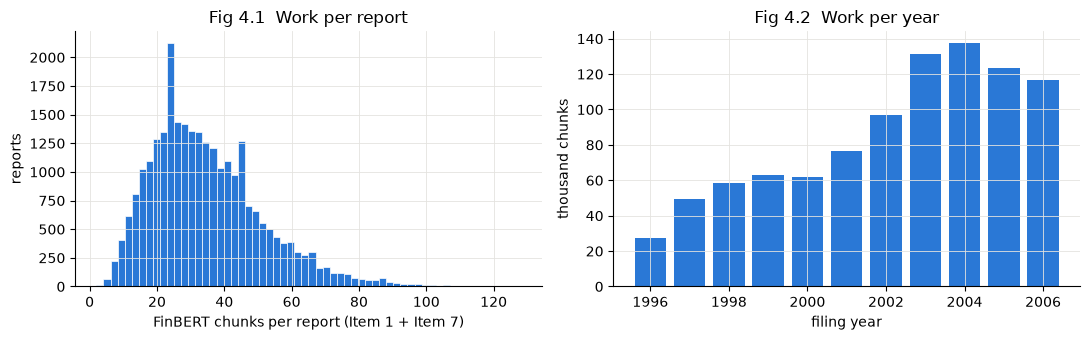

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(ds["chunks"], bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
ax[0].set(xlabel="FinBERT chunks per report (Item 1 + Item 7)", ylabel="reports", title="Fig 4.1  Work per report")
per_year = ds.groupby("year")["chunks"].sum() / 1e3
ax[1].bar(per_year.index, per_year.values, color=BLUE, width=0.8)
ax[1].set(xlabel="filing year", ylabel="thousand chunks", title="Fig 4.2  Work per year")
plt.tight_layout(); plt.show()

## 2. Experiment A: device, precision and batch size

We take real chunks from 2006 reports (Item 1 and Item 7, cut exactly as `extract_finbert.py` does), and time how many
chunks per second FinBERT processes under each setting:

- **device**: the laptop's CPU, the laptop's GPU (Apple `mps`), and, from Alex's run, a Colab **T4** GPU (`cuda`);
- **precision**: 32-bit numbers (`fp32`) vs 16-bit (`fp16`, what both full runs used; `extract_finbert.py --smoke`
  checked that fp16 and fp32 give near-identical vectors). Half precision halves the memory traffic and, on GPUs
  built for it, uses faster arithmetic (Micikevicius et al., 2018);
- **batch size**: how many chunks go through the network at once. Bigger batches keep a GPU busier, until it is full.

Each laptop setting is timed twice after one warm-up batch (the first call to a GPU is slow while it compiles), and we
keep the faster run (the slower is usually disturbed by something else on the machine). We also time the
**tokeniser** (text to FinBERT's word pieces), which runs on the CPU: if it were slower than FinBERT it would be the
bottleneck, and adding GPUs would not help.

**The T4 row uses a different FinBERT** (Yang et al., 2020, which Alex tested as a second encoder). It has the same
architecture as ours (BERT-base: 12 layers, 768 wide, about 110 million parameters; Devlin et al., 2019), and the
arithmetic per chunk is set by the architecture, not by the trained weights, so its speed per chunk stands in for
ours. Alex timed 512 chunks at batch sizes 8 to 128, in half precision.

In [4]:
if MEASURE:
    import gc, sys, time
    import torch, transformers
    sys.path.insert(0, str(ROOT / "Oscar"))   # reuse the exact chunking and model loading of the full run
    from extract_finbert import CHUNK, MODEL, load_model, load_plan, load_texts
    transformers.logging.set_verbosity_error()   # hide "sequence longer than 512": we chunk it ourselves

    DEVICES = ["cpu"] + (["mps"] if torch.backends.mps.is_available() else []) + (["cuda"] if torch.cuda.is_available() else [])
    GPU = DEVICES[-1] if len(DEVICES) > 1 else None
    print("torch", torch.__version__, "| devices:", DEVICES)

    plan = load_plan()
    rows = plan[plan["year"] == 2006].head(150)
    texts = load_texts(2006, rows)
    docs = [t for k in rows["key"] for t in texts[k] if t]

    tok = transformers.AutoTokenizer.from_pretrained(MODEL)
    t0 = time.perf_counter()
    ids = [tok(d, add_special_tokens=False)["input_ids"] for d in docs]
    tok_secs = time.perf_counter() - t0
    chunks = [x[i:i + CHUNK] for x in ids for i in range(0, len(x), CHUNK)]

    def sync(device):
        if device == "mps":
            torch.mps.synchronize()
        elif device == "cuda":
            torch.cuda.synchronize()

    def time_forward(model, chunks, device, batch):
        # seconds for FinBERT to turn `chunks` into CLS vectors, batched as in extract_finbert.embed()
        sync(device)
        t = time.perf_counter()
        with torch.inference_mode():
            for i in range(0, len(chunks), batch):
                enc = tok.pad({"input_ids": [[tok.cls_token_id] + c + [tok.sep_token_id] for c in chunks[i:i + batch]]},
                              return_tensors="pt")
                model(**{k: v.to(device) for k, v in enc.items()}).last_hidden_state[:, 0].float().cpu()
        sync(device)
        return time.perf_counter() - t

    def free(model, device):
        del model
        gc.collect()
        if device == "mps":
            torch.mps.empty_cache()
        elif device == "cuda":
            torch.cuda.empty_cache()

    # (device, precision, batch sizes, chunks to time). The CPU is slow, so it gets fewer chunks.
    configs = [("cpu", torch.float32, [1, 8, 32], 64)]
    if GPU:
        configs += [(GPU, torch.float32, [1, 8, 32, 64], 256), (GPU, torch.float16, [1, 8, 32, 64], 256)]
    results, load_secs = [], {}
    for device, dtype, batches, n in configs:
        t = time.perf_counter()
        _, model = load_model(device, dtype)
        sync(device)
        load_secs[(device, dtype)] = time.perf_counter() - t
        time_forward(model, chunks[:8], device, 8)   # warm-up
        for b in batches:
            secs = min(time_forward(model, chunks[:n], device, b) for _ in range(2))
            results.append({"device": device, "precision": str(dtype).replace("torch.float", "fp"),
                            "batch": b, "chunks": n, "seconds": secs, "chunks_per_s": n / secs})
            print(results[-1])
        free(model, device)
    pd.DataFrame(results).to_csv(SAVED["speed"], index=False)

    gpu_dtype = torch.float16 if GPU else torch.float32
    pd.Series({
        "tokeniser_chunks_per_s": len(chunks) / tok_secs,
        "text_bytes_per_chunk": sum(len(d.encode("utf-8")) for d in docs) / len(chunks),
        "tokens_per_chunk": sum(len(c) for c in chunks) / len(chunks),
        "model_load_s": load_secs[(GPU or "cpu", gpu_dtype)],
    }, name="value").rename_axis("name").to_csv(SAVED["misc"])

tokeniser: 1,982 chunks/s on one laptop CPU core
raw text: about 2.6 kB per chunk; 497 tokens per chunk on average


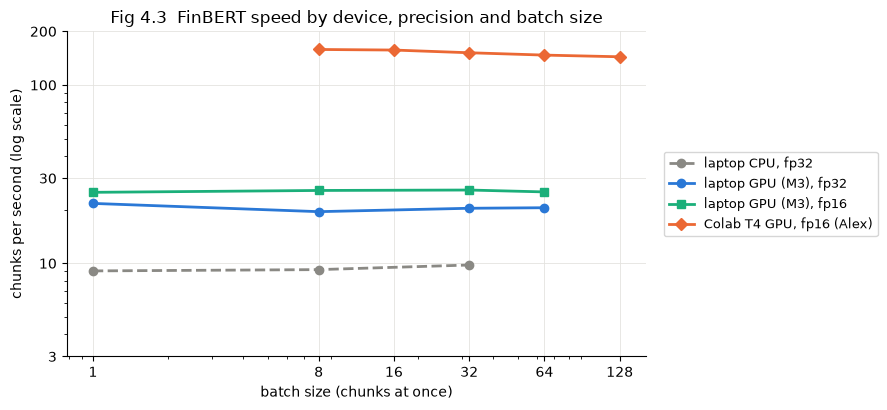

machine   Colab T4 laptop CPU laptop GPU      
precision     fp16       fp32       fp16  fp32
batch                                         
1              NaN        9.1       25.0  21.7
8            158.2        9.2       25.6  19.5
16           157.1        NaN        NaN   NaN
32           151.7        9.8       25.8  20.4
64           147.1        NaN       25.1  20.5
128          144.0        NaN        NaN   NaN

In [5]:
speed = pd.read_csv(SAVED["speed"])
misc = pd.read_csv(SAVED["misc"], index_col="name")["value"]
t4 = pd.read_csv(OUTPUT / "alex-04-embedding-timing.csv")   # Alex, Colab T4, Yang et al.'s FinBERT, fp16

print(f"tokeniser: {misc['tokeniser_chunks_per_s']:,.0f} chunks/s on one laptop CPU core")
print(f"raw text: about {misc['text_bytes_per_chunk'] / 1e3:.1f} kB per chunk; {misc['tokens_per_chunk']:.0f} tokens per chunk on average")

series = [(speed.query("device == 'cpu'"), "laptop CPU, fp32", GREY, "o--"),
          (speed.query("device != 'cpu' and precision == 'fp32'"), "laptop GPU (M3), fp32", BLUE, "o-"),
          (speed.query("device != 'cpu' and precision == 'fp16'"), "laptop GPU (M3), fp16", AQUA, "s-"),
          (t4.rename(columns={"chunks_per_second": "chunks_per_s"}), "Colab T4 GPU, fp16 (Alex)", ORANGE, "D-")]
fig, ax = plt.subplots(figsize=(9, 4.2))
for g, label, colour, style in series:
    ax.plot(g["batch"], g["chunks_per_s"], style, color=colour, label=label)
ax.set(xscale="log", yscale="log", xlabel="batch size (chunks at once)", ylabel="chunks per second (log scale)",
       title="Fig 4.3  FinBERT speed by device, precision and batch size")
ax.set_xticks([1, 8, 16, 32, 64, 128], labels=["1", "8", "16", "32", "64", "128"])
ax.set_yticks([3, 10, 30, 100, 200], labels=["3", "10", "30", "100", "200"])
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=9); plt.tight_layout(); plt.show()

table = pd.concat([speed.assign(machine=np.where(speed["device"] == "cpu", "laptop CPU", "laptop GPU"))
                        [["machine", "precision", "batch", "chunks_per_s"]],
                   t4.assign(machine="Colab T4", precision="fp16").rename(columns={"chunks_per_second": "chunks_per_s"})
                        [["machine", "precision", "batch", "chunks_per_s"]]])
table.pivot_table(index="batch", columns=["machine", "precision"], values="chunks_per_s").round(1)

## 3. Experiment B: does the time grow in proportion to the data?

If FinBERT's time is a fixed start-up cost plus a constant cost per chunk, then `time = a + b × chunks`, and the 1000×
estimate is that line extended. We time 32 up to 1,024 chunks with the setting of the full run (laptop GPU, fp16,
batch 32) and fit the line by least squares.

time = -0.39 s + 47.0 ms per chunk   (R² = 0.9974)  =>  21.3 chunks/s
Experiment A at the same setting: 25.8 chunks/s


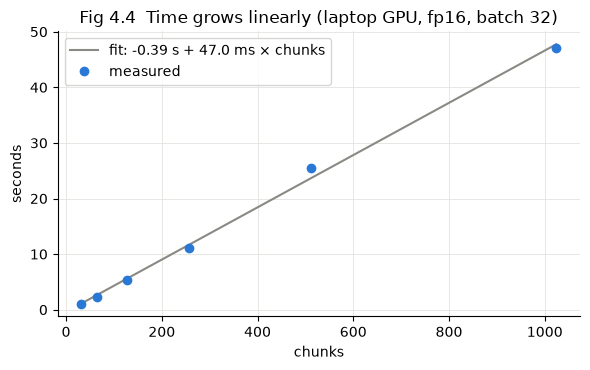

In [6]:
if MEASURE:
    device = GPU or "cpu"
    sizes = [n for n in [32, 64, 128, 256, 512, 1024] if n <= len(chunks)]
    if not GPU:
        sizes = sizes[:4]   # the CPU is too slow for the big sizes
    _, model = load_model(device, gpu_dtype)
    time_forward(model, chunks[:8], device, 8)
    pd.DataFrame({"chunks": sizes, "seconds": [time_forward(model, chunks[:n], device, 32) for n in sizes]}
                 ).to_csv(SAVED["growth"], index=False)
    free(model, device)

grow = pd.read_csv(SAVED["growth"])
b, a = np.polyfit(grow["chunks"], grow["seconds"], 1)
pred = a + b * grow["chunks"]
r2 = 1 - ((grow["seconds"] - pred) ** 2).sum() / ((grow["seconds"] - grow["seconds"].mean()) ** 2).sum()
RATE = 1 / b   # laptop GPU chunks per second, once any fixed cost is paid
print(f"time = {a:.2f} s + {b * 1000:.1f} ms per chunk   (R² = {r2:.4f})  =>  {RATE:.1f} chunks/s")

# the laptop's speed-test rate at the full run's setting (GPU, fp16, batch 32), from Experiment A
LAPTOP_BENCH = speed.query("device != 'cpu' and precision == 'fp16' and batch == 32")["chunks_per_s"].iloc[0]
print(f"Experiment A at the same setting: {LAPTOP_BENCH:.1f} chunks/s")

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(grow["chunks"], pred, "-", color=GREY, lw=1.5, label=f"fit: {a:.2f} s + {b * 1000:.1f} ms × chunks")
ax.plot(grow["chunks"], grow["seconds"], "o", color=BLUE, label="measured")
ax.set(xlabel="chunks", ylabel="seconds", title="Fig 4.4  Time grows linearly (laptop GPU, fp16, batch 32)")
ax.legend(); plt.tight_layout(); plt.show()

The fitted start-up cost `a` is about zero (it can come out slightly negative, which only means it is too small to
measure against the timing noise). So FinBERT's cost is, to a very good approximation, **a fixed price per chunk**.

The *slope* is less steady than the straight line. In our saved run it gives 21.3 chunks/s, against 25.8 at the same
setting in Experiment A a few minutes earlier (and 25.4 in an earlier run of this test, `Oscar/05-Scaling.ipynb`). This
test runs last, after about five minutes of continuous load, and the drop matches the slowdown seen in the full run
(section 4). So we use Experiment A's figure, `LAPTOP_BENCH`, as the laptop's speed-test rate from here on, and this
section only for the shape of the line.

## 4. The speed tests against the full runs

Both full runs went slower than their speed test, which is the first sign of what limits scaling.

- **Laptop** (all 943,001 chunks, ProsusAI FinBERT, 12–13 Nov). `extract_finbert.py` saved a file every 250 reports, so
  the files' save times give its speed through the night. The run's output is in the group's OneDrive folder; the
  timeline read from it is saved in `data/output/scaling-fullrun.csv` for anyone without that folder.
- **Colab T4** (480,332 Item 7 chunks, Yang FinBERT, Alex): **68 minutes**, a steady 117–118 chunks/s throughout
  (`Alex/04-Second-encoder.ipynb`, section 3 log), against 158 chunks/s in the speed test at the batch size it used.

laptop: 11.9 h for the timed shards; sustained 21.8 chunks/s vs 25.8 in the speed test (-15%); first hour 23.8 chunks/s
T4: sustained 118 chunks/s vs 158 in the speed test (-26%)


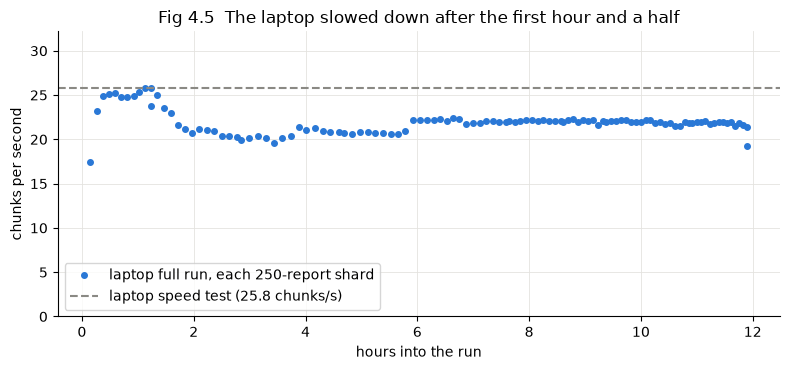

In [7]:
if SHARDS.exists() and (MEASURE or not SAVED["fullrun"].exists()):
    # the chunks in each shard, rebuilt from dataset.csv in the order extract_finbert.py wrote them
    src = pd.read_csv(PROCESSED / "item7_source.csv")
    src = src[src["usable"]].sort_values(["year", "key"]).reset_index(drop=True)
    src = src.merge(ds[["key", "chunks"]], on="key", how="left")
    src["shard"] = src.groupby("year").cumcount() // 250
    sh = src.groupby(["year", "shard"])["chunks"].sum().reset_index()
    sh["saved_at"] = [(SHARDS / f"{y}_{s:03d}.npz").stat().st_mtime for y, s in zip(sh["year"], sh["shard"])]
    sh.sort_values("saved_at").to_csv(SAVED["fullrun"], index=False)

run = pd.read_csv(SAVED["fullrun"]).sort_values("saved_at").reset_index(drop=True)
run["seconds"] = run["saved_at"].diff()            # time since the previous shard was saved
run["rate"] = run["chunks"] / run["seconds"]
run["hours_in"] = (run["saved_at"] - run["saved_at"].iloc[0]) / 3600
run = run.iloc[1:]                                  # the first shard has no start time
LAPTOP_SUSTAINED = run["chunks"].sum() / run["seconds"].sum()
first_hour = run.loc[run["hours_in"] <= 1, "rate"].mean()

T4_BENCH = t4["chunks_per_second"].max()            # speed test, best batch (the one the full run used)
T4_SUSTAINED = 480_332 / (68 * 60)                  # Alex's full run
print(f"laptop: {run['hours_in'].iloc[-1]:.1f} h for the timed shards; sustained {LAPTOP_SUSTAINED:.1f} chunks/s "
      f"vs {LAPTOP_BENCH:.1f} in the speed test ({LAPTOP_SUSTAINED / LAPTOP_BENCH - 1:+.0%}); first hour {first_hour:.1f} chunks/s")
print(f"T4: sustained {T4_SUSTAINED:.0f} chunks/s vs {T4_BENCH:.0f} in the speed test ({T4_SUSTAINED / T4_BENCH - 1:+.0%})")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(run["hours_in"], run["rate"], "o", color=BLUE, ms=4, label="laptop full run, each 250-report shard")
ax.axhline(LAPTOP_BENCH, color=GREY, ls="--", lw=1.5, label=f"laptop speed test ({LAPTOP_BENCH:.1f} chunks/s)")
ax.set(xlabel="hours into the run", ylabel="chunks per second", ylim=(0, LAPTOP_BENCH * 1.25),
       title="Fig 4.5  The laptop slowed down after the first hour and a half")
ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

The two runs fall short for different reasons:

- **The laptop** ran at about its speed-test rate for the first hour and a half, then dropped to 20–22 chunks/s for
  the remaining ten hours, whichever year it was reading (Fig 4.5): about 15% lower overall. A step down that stays down is what a laptop does when
  it gets hot and slows itself to cool (thermal throttling); we did not log the temperature, so this is our reading of
  the pattern, not a measurement.
- **The T4** ran at a steady rate from start to finish, so it was not heat. Its full run did something the speed test
  did not: for each shard, read the text from Google Drive and tokenise it on Colab's CPU, *then* send it to the GPU.
  The two steps took turns, so the GPU waited while the CPU worked. If each chunk costs `1/g` seconds on the GPU and
  `1/p` on the CPU, run one after the other the rate is `1 / (1/g + 1/p)`. With `g` = 158 and the measured 117, the CPU
  step works out at `p` ≈ 460 chunks/s.

This matters for scaling, because the CPU step does not speed up when the GPU does (Amdahl, 1967): the faster the
GPU, the larger the share of time it spends waiting. If the CPU step instead runs **alongside** the GPU (a separate
process preparing the next batch while the GPU works, as PyTorch's `DataLoader` workers do), the rate is the slower of
the two, `min(g, p)`, not their sum of times.

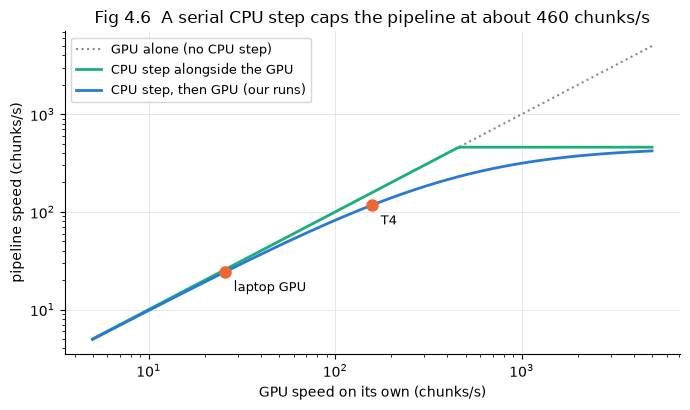

                              GPU on its own (chunks/s)  share of time the GPU waits
laptop GPU                                        25.76                         0.05
T4                                               158.23                         0.26
a GPU 4x a T4 (hypothetical)                     632.90                         0.58


In [8]:
P_CPU = 1 / (1 / T4_SUSTAINED - 1 / T4_BENCH)      # implied CPU-side rate (read + tokenise) in Alex's run
g = np.geomspace(5, 5000, 200)
serial, overlap = 1 / (1 / g + 1 / P_CPU), np.minimum(g, P_CPU)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(g, g, ":", color=GREY, lw=1.5, label="GPU alone (no CPU step)")
ax.plot(g, overlap, "-", color=AQUA, label="CPU step alongside the GPU")
ax.plot(g, serial, "-", color=BLUE, label="CPU step, then GPU (our runs)")
for name, rate in [("laptop GPU", LAPTOP_BENCH), ("T4", T4_BENCH)]:
    ax.plot(rate, 1 / (1 / rate + 1 / P_CPU), "o", color=ORANGE, ms=8, zorder=3)
    ax.annotate(name, (rate, 1 / (1 / rate + 1 / P_CPU)), xytext=(6, -14), textcoords="offset points", fontsize=9)
ax.set(xscale="log", yscale="log", xlabel="GPU speed on its own (chunks/s)", ylabel="pipeline speed (chunks/s)",
       title=f"Fig 4.6  A serial CPU step caps the pipeline at about {P_CPU:.0f} chunks/s")
ax.legend(loc="upper left", fontsize=9); plt.tight_layout(); plt.show()

waiting = lambda gpu: (1 / P_CPU) / (1 / gpu + 1 / P_CPU)
print(pd.DataFrame({"GPU on its own (chunks/s)": [LAPTOP_BENCH, T4_BENCH, 4 * T4_BENCH],
                    "share of time the GPU waits": [waiting(x) for x in [LAPTOP_BENCH, T4_BENCH, 4 * T4_BENCH]]},
                   index=["laptop GPU", "T4", "a GPU 4x a T4 (hypothetical)"]).to_string(float_format="{:,.2f}".format))

Two fixes follow, and neither needs a bigger GPU:

- **Overlap** the CPU step with the GPU, so the T4 would run at its speed-test rate.
- **Tokenise once, ahead of time, and store the token ids** instead of the text. A token id fits in 2 bytes (our
  FinBERT's vocabulary has 30,522 word pieces, under the 65,536 that 2 bytes can count), so a chunk becomes about
  1 kB of ids against about 2.6 kB of text. Tokenising is then a separate job that can be spread over many cheap CPU
  machines, and there is less to move to each GPU (section 5).

## 5. What 1000× would take

**Assumptions** (each stated so it can be challenged):

- 1000× more data means 1000× as many chunks. 1000× our corpus is about 27 million reports, more 10-Ks than have ever
  been filed, so in practice it would mean adding other text: 8-K filings, earnings-call transcripts, news.
- Per-GPU speeds are the ones measured above: the laptop's sustained rate, and the T4's sustained rate (as our runs
  were) or its speed-test rate (with the CPU step overlapped, section 4). A newer data-centre GPU would be faster.
- Training speed of the attention network is **Alex's measurement on a T4**: 4,783 reports per second, Item 7,
  batch 64 (`Alex/03-Attention-network.ipynb`, section 5).

In [9]:
TRAIN_RATE = 4783                      # reports/s, attention network on a T4 (Alex/03-Attention-network.ipynb, section 5)
c1000 = n_chunks * 1000
rows_ = []
for scale in [1, 1000]:
    c = n_chunks * scale
    rows_.append({"scale": f"{scale}×", "reports": n_reports * scale, "chunks": c,
                  "raw text (GB)": c * misc["text_bytes_per_chunk"] / 1e9,
                  "FinBERT output (GB)": c * BYTES_PER_VECTOR / 1e9,
                  "1 laptop GPU (days)": c / LAPTOP_SUSTAINED / 86400,
                  "1 T4, as run (days)": c / T4_SUSTAINED / 86400,
                  "1 T4, overlapped (days)": c / T4_BENCH / 86400,
                  "1 epoch of attention net on a T4 (min)": n_reports * scale / TRAIN_RATE / 60})
print(pd.DataFrame(rows_).set_index("scale").T.to_string(float_format="{:,.1f}".format))

scale                                         1×         1000×
reports                                 27,142.0  27,142,000.0
chunks                                 943,001.0 943,001,000.0
raw text (GB)                                2.4       2,421.0
FinBERT output (GB)                          1.4       1,448.4
1 laptop GPU (days)                          0.5         500.7
1 T4, as run (days)                          0.1          92.7
1 T4, overlapped (days)                      0.1          69.0
1 epoch of attention net on a T4 (min)       0.1          94.6


### Map/reduce: does FinBERT split across many GPUs efficiently?

Every chunk is read independently: no chunk needs another chunk's result. So the reading step is a **map** (Dean &
Ghemawat, 2004): give each of `N` GPUs `1/N` of the chunks. The **reduce** only collects each report's chunk vectors
together, which is bookkeeping (what `Oscar/build_dataset.py` does in seconds).

Two costs do **not** shrink as GPUs are added:

- each worker loads FinBERT once (measured: about a second);
- the input has to be **read from storage and sent to the workers**. If it all comes from one shared store, that
  store's bandwidth is a fixed limit however many GPUs are waiting. We **assume** 1 GB/s (`BANDWIDTH_GB_S`, change it to
  test): a round number for one shared network drive, not a measurement.

So with `N` workers

    time(N) = start-up + input size / bandwidth + chunks / (N × rate per GPU)

and the **efficiency** (how close we get to `N` times faster) is `time(1) / (N × time(N))`. This is Amdahl's law: the
part that cannot be split eventually dominates. Treating the transfer as a separate step is the pessimistic case; if
the GPUs start as soon as their first data arrives, the time is nearer the larger of the two terms than their sum.
We compare three set-ups: the laptop's GPU reading text, a T4 reading text, and a T4 reading pre-tokenised ids.

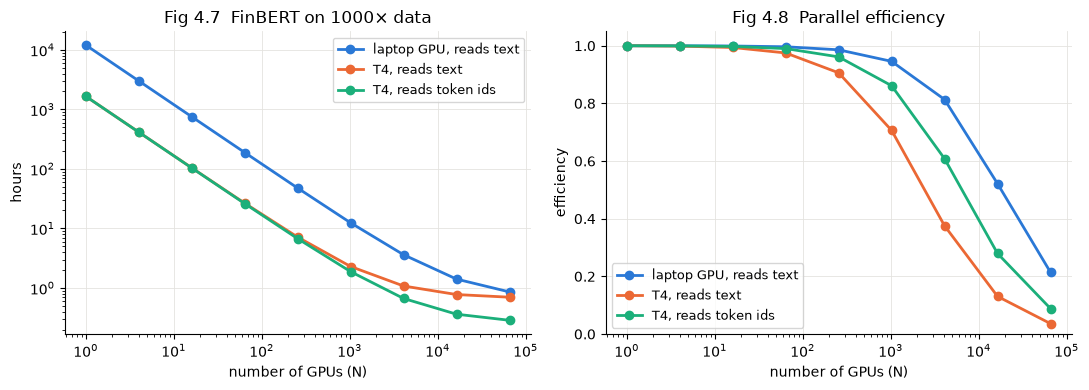

laptop GPU, reads text: moving the input takes 0.67 h at 1 GB/s
T4, reads text: moving the input takes 0.67 h at 1 GB/s
T4, reads token ids: moving the input takes 0.26 h at 1 GB/s

hours
       laptop GPU, reads text  T4, reads text  T4, reads token ids
GPUs                                                              
1                   12,017.60        1,656.18             1,655.77
4                    3,004.90          414.55               414.14
16                     751.73          104.14               103.73
64                     188.44           26.54                26.13
256                     47.61            7.14                 6.73
1024                    12.41            2.29                 1.88
4096                     3.61            1.08                 0.66
16384                    1.41            0.77                 0.36
65536                    0.86            0.70                 0.29

efficiency
       laptop GPU, reads text  T4, reads text  T4, reads token 

In [10]:
BANDWIDTH_GB_S = 1.0                   # ASSUMED, not measured: one shared store feeding every worker
STARTUP = misc["model_load_s"]
N = np.array([1, 4, 16, 64, 256, 1024, 4096, 16384, 65536])
setups = {"laptop GPU, reads text": (LAPTOP_SUSTAINED, misc["text_bytes_per_chunk"], BLUE),
          "T4, reads text": (T4_BENCH, misc["text_bytes_per_chunk"], ORANGE),
          "T4, reads token ids": (T4_BENCH, 2 * misc["tokens_per_chunk"], AQUA)}

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
summary = {}
for name, (rate, bytes_per_chunk, colour) in setups.items():
    transfer = c1000 * bytes_per_chunk / 1e9 / BANDWIDTH_GB_S
    t_N = STARTUP + transfer + c1000 / (N * rate)
    eff = t_N[0] / (N * t_N)
    ax[0].loglog(N, t_N / 3600, "o-", color=colour, label=name)
    ax[1].semilogx(N, eff, "o-", color=colour, label=name)
    summary[name] = pd.Series(t_N / 3600, index=N), pd.Series(eff, index=N), transfer
ax[0].set(xlabel="number of GPUs (N)", ylabel="hours", title="Fig 4.7  FinBERT on 1000× data")
ax[1].set(xlabel="number of GPUs (N)", ylabel="efficiency", ylim=(0, 1.05), title="Fig 4.8  Parallel efficiency")
ax[0].legend(fontsize=9); ax[1].legend(fontsize=9, loc="lower left")
plt.tight_layout(); plt.show()

hours = pd.DataFrame({k: v[0] for k, v in summary.items()}).rename_axis("GPUs")
effs = pd.DataFrame({k: v[1] for k, v in summary.items()}).rename_axis("GPUs")
for k, v in summary.items():
    print(f"{k}: moving the input takes {v[2] / 3600:.2f} h at {BANDWIDTH_GB_S:g} GB/s")
print("\nhours\n" + hours.to_string(float_format="{:,.2f}".format))
print("\nefficiency\n" + effs.to_string(float_format="{:,.2f}".format))

## 6. A realistic ladder: from our corpus to every 10-K up to today

1000× our corpus is more 10-Ks than exist, so section 5 is a thought experiment. The realistic ways to grow are
steps up a ladder, each one a larger share of the 10-Ks actually filed. Two sources, fetched by
`Oscar/scale_sources.py` and saved in `data/output/`:

- **How many 10-Ks were filed each year, 1996–2025**: counted from the SEC's own EDGAR index of every filing
  (`scaling-sec-10k-counts.csv`). We count 10-K, 10-K405 and 10-KT, not amendments and not the small-company 10-KSB,
  which neither Kogan's corpus nor EDGAR-CORPUS includes. For 1997–2006 these counts are within about 2% of
  EDGAR-CORPUS's (`Oscar/02-Merge-Kogan-EDGAR.ipynb`). 1996 is low because filing on EDGAR only became compulsory
  during that year.
- **How long reports are now**: word counts of every section in EDGAR-CORPUS's test split, a random sample of about
  a tenth of each year, for 2006, 2013 and 2020 (`scaling-edgar-lengths.csv`).

**Assumptions** (each can be changed below):

- Kogan's corpus covers only some filers: those whose shares CRSP prices and whose Item 7 Kogan's script could
  find. Extending "our companies" to today keeps the share of filers we have in 2002–2006.
- A report's FinBERT chunks grow with its word count. After 2006 we scale our 2006 chunks per report by the growth in
  mean words in the EDGAR-CORPUS sample, straight-line between the sample years, and flat after 2020.
- "Whole 10-K" multiplies by the sample's ratio of all sections to Items 1 and 7 (the 2006 ratio for earlier years).
- Speeds are the T4's from section 4: as run (118 chunks/s), and with the CPU step overlapped (158 chunks/s).

In [11]:
sec = pd.read_csv(OUTPUT / "scaling-sec-10k-counts.csv").groupby("year")["filings"].sum()
lengths = pd.read_csv(OUTPUT / "scaling-edgar-lengths.csv", index_col="year")
ours = ds.groupby("year").agg(reports=("key", "size"), chunks=("chunks", "sum"))
ours["chunks_per_report"] = ours["chunks"] / ours["reports"]
ours["share_of_filers"] = ours["reports"] / sec.loc[ours.index]

ALL_YEARS = sec.index                                     # 1996-2025
SHARE = ours.loc[2002:2006, "share_of_filers"].mean()     # assumption: our coverage of filers, kept at its 2002-06 level

def interp(col):
    # a per-year curve from the three sample years: straight lines between them, flat outside
    return pd.Series(np.interp(ALL_YEARS, lengths.index, lengths[col]), index=ALL_YEARS)

growth = interp("mean_items_1_7") / lengths.loc[2006, "mean_items_1_7"]
growth[ALL_YEARS <= 2006] = 1.0                          # before 2006 we have our own chunk counts
cpr = pd.Series(ours.loc[2006, "chunks_per_report"], index=ALL_YEARS) * growth
cpr.loc[ours.index] = ours["chunks_per_report"]          # our measured chunks per report, 1996-2006
whole = interp("mean_all_sections") / interp("mean_items_1_7")
whole[ALL_YEARS < 2006] = whole[2006]

later = ALL_YEARS > 2006
ladder = pd.DataFrame({
    "our corpus (Kogan's companies, 1996-2006)": (ours["reports"].sum(), ours["chunks"].sum()),
    "+ extended to 2025 (same share of filers)": (ours["reports"].sum() + (SHARE * sec[later]).sum(),
                                                  ours["chunks"].sum() + (SHARE * sec[later] * cpr[later]).sum()),
    "every 10-K filer, 1996-2025": (sec.sum(), (sec * cpr).sum()),
    "every 10-K filer, whole 10-K": (sec.sum(), (sec * cpr * whole).sum()),
    "the brief's 1000x": (n_reports * 1000, n_chunks * 1000),
}, index=["reports", "chunks"]).T
ladder["x our data"] = ladder["chunks"] / n_chunks
ladder["FinBERT output (GB)"] = ladder["chunks"] * BYTES_PER_VECTOR / 1e9
ladder["1 T4, as run (days)"] = ladder["chunks"] / T4_SUSTAINED / 86400
ladder["1 T4, overlapped (days)"] = ladder["chunks"] / T4_BENCH / 86400
ladder["T4s to finish in a day"] = np.ceil(ladder["1 T4, overlapped (days)"]).astype(int)

print(f"our share of 10-K filers, 2002-2006: {SHARE:.0%}  (by year: "
      + ", ".join(f"{y}: {v:.0%}" for y, v in ours["share_of_filers"].items()) + ")")
print(f"10-Ks filed 1996-2025: {sec.sum():,}; mean words, Items 1+7 -> whole 10-K: "
      + "; ".join(f"{y}: {r.mean_items_1_7:,.0f} -> {r.mean_all_sections:,.0f}" for y, r in lengths.iterrows()))
ladder.style.format({"reports": "{:,.0f}", "chunks": "{:,.0f}", "x our data": "{:,.1f}", "FinBERT output (GB)": "{:,.1f}",
                     "1 T4, as run (days)": "{:,.1f}", "1 T4, overlapped (days)": "{:,.1f}", "T4s to finish in a day": "{:,}"})

our share of 10-K filers, 2002-2006: 34%  (by year: 1996: 20%, 1997: 20%, 1998: 21%, 1999: 22%, 2000: 22%, 2001: 25%, 2002: 29%, 2003: 38%, 2004: 37%, 2005: 35%, 2006: 34%)
10-Ks filed 1996-2025: 249,368; mean words, Items 1+7 -> whole 10-K: 2006: 11,634 -> 30,818; 2013: 12,128 -> 35,873; 2020: 13,550 -> 43,876


,reports,chunks,x our data,FinBERT output (GB),"1 T4, as run (days)","1 T4, overlapped (days)",T4s to finish in a day
"our corpus (Kogan's companies, 1996-2006)","27,142","943,001",1.0,1.4,0.1,0.1,1
+ extended to 2025 (same share of filers),"78,635","3,114,014",3.3,4.8,0.3,0.2,1
"every 10-K filer, 1996-2025","249,368","9,615,624",10.2,14.8,0.9,0.7,1
"every 10-K filer, whole 10-K","249,368","27,917,047",29.6,42.9,2.7,2.0,3
the brief's 1000x,"27,142,000","943,001,000","1,000.0","1,448.4",92.7,69.0,69


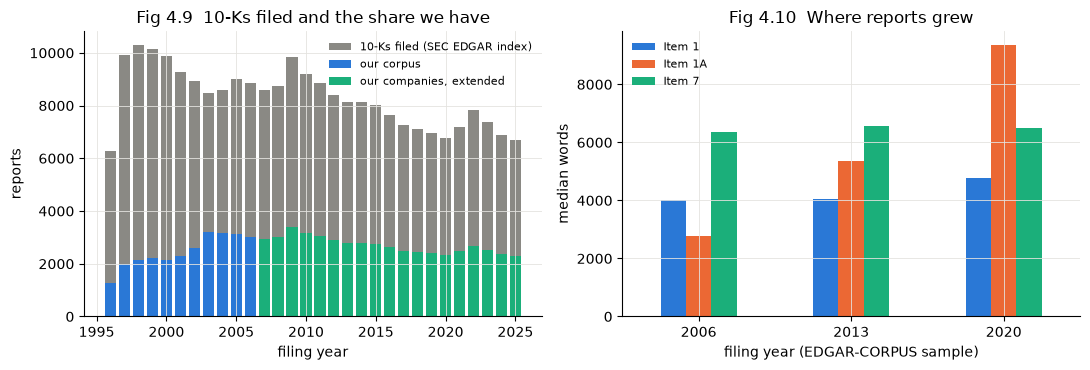

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(sec.index, sec.values, color=GREY, width=0.8, label="10-Ks filed (SEC EDGAR index)")
ax[0].bar(ours.index, ours["reports"], color=BLUE, width=0.8, label="our corpus")
ax[0].bar(ALL_YEARS[later], SHARE * sec[later], color=AQUA, width=0.8, label="our companies, extended")
ax[0].set(xlabel="filing year", ylabel="reports", title="Fig 4.9  10-Ks filed and the share we have")
ax[0].legend(frameon=False, fontsize=8)
cols = ["item1", "item1A", "item7"]
w = lengths[[f"median_{c}" for c in cols]].rename(columns=lambda c: c.replace("median_", "Item ").replace("item", ""))
w.plot.bar(ax=ax[1], color=[BLUE, ORANGE, AQUA], rot=0)
ax[1].set(xlabel="filing year (EDGAR-CORPUS sample)", ylabel="median words", title="Fig 4.10  Where reports grew")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

The ladder changes the picture of section 5:

- **Every realistic step runs on a single GPU.** Bringing our companies up to 2025 (3.3× our data, about 7 hours),
  all 10-K filers (10×, under a day) and even every section of every 10-K (30×, under three days) all run on one T4. None needs the cluster of section 5,
  which only the brief's 1000× requires, and in practice that means adding other text (quarterly 10-Qs, 8-Ks,
  earnings-call transcripts, news), not more 10-Ks.
- **Reports grew in the sections we left out.** Items 1 and 7 barely grew after 2006 (Fig 4.10); the whole 10-K grew
  by about 40%, mostly through Risk Factors (Item 1A), which tripled. So a modern study would add Item 1A, and
  that, not the number of reports, is what makes the text bigger.
- **The limit is the labels, not the computing.** Each rung needs a volatility label for every report, so daily
  prices for every company, including those later delisted. Kogan's labels stop in 2006, and only CRSP (through
  WRDS, restricted at Bristol) covers delisted companies; Yahoo labelled only 26% of 2004's reports and lost the
  riskier ones (`02-Data.ipynb`, section 1). And not every filer has traded shares at all (funds, trusts, companies
  with only debt), so "every 10-K filer" is an upper bound on what could be labelled.

## 7. Training costs: models on saved vectors, word counts, and fine-tuning

Sections 1–5 cover reading the text once. The models are then trained on the result, and their cost depends on what
they read:

- **Models on the saved FinBERT vectors** (ridge, attention network): 768 numbers per chunk, so training is cheap
  (section 5).
- **Word-count models** (Louis): a sparse matrix of word counts per report, built on the CPU. Louis measured these
  in `Louis/05-Neural-Models-Combined-v2.ipynb`; the figures are copied from its output below.
- **Fine-tuning** (Alex, `Alex/05-Fine-tuning.ipynb`): FinBERT itself is trained, so every training chunk goes through
  the 110-million-parameter network forwards *and* backwards. Alex ran it on a Colab T4 for one test year (2006, paper
  window) and one seed, reading 4 random chunks per report per step to keep an epoch affordable. The per-epoch log is
  `data/output/alex-05-history.csv`; the frozen-network runs it is compared with are in `alex-04-runs.csv`.

In [13]:
ft = pd.read_csv(OUTPUT / "alex-05-history.csv")             # Alex, Colab T4, one seed, 3 epochs
frozen_runs = pd.read_csv(OUTPUT / "alex-04-runs.csv")          # Alex, frozen attention network on Yang's vectors
FT_TRAIN_RATE = ft["train_chunks"].sum() / ft["train_seconds"].sum()        # chunks/s, forwards and backwards
FT_EPOCH_CHUNKS = ft["train_chunks"].iloc[0]
ft_hours = (ft["train_seconds"].sum() + ft["val_seconds"].sum()) / 3600    # 3 epochs + early-stopping scoring
frozen_minutes_60 = frozen_runs["seconds"].sum() / 60 * 60 / len(frozen_runs)

# Louis's word-count models: copied from the output of Louis/05-Neural-Models-Combined-v2.ipynb (section on scaling)
LOUIS_COUNT_SECONDS = 91.2       # building the word-count matrix for all 27,142 reports, one CPU core
LOUIS_SPARSE_GB = 0.193          # the matrix stored sparse (CSR)

costs = pd.Series({
    "fine-tuning: training speed on a T4 (chunks/s)": f"{FT_TRAIN_RATE:.0f}",
    "  against reading only, T4 speed test (chunks/s)": f"{T4_BENCH:.0f}",
    "fine-tuning: one epoch (min)": f"{ft['train_seconds'].mean() / 60:.0f}",
    "fine-tuning: one test year, one seed, 3 epochs (GPU-hours)": f"{ft_hours:.1f}",
    "frozen attention network: 60 runs on Yang's vectors (min)": f"{frozen_minutes_60:.0f}",
    "fine-tuning at 1000x: one epoch (T4-hours)": f"{FT_EPOCH_CHUNKS * 1000 / FT_TRAIN_RATE / 3600:,.0f}",
    "word counts: build matrix, 1 core (s) / at 1000x (h)": f"{LOUIS_COUNT_SECONDS:.0f} / {LOUIS_COUNT_SECONDS * 1000 / 3600:.1f}",
    "word counts: sparse matrix (GB) / at 1000x (GB)": f"{LOUIS_SPARSE_GB:.2f} / {LOUIS_SPARSE_GB * 1000:,.0f}",
})
print(costs.to_string())

fine-tuning: training speed on a T4 (chunks/s)                        40
  against reading only, T4 speed test (chunks/s)                     158
fine-tuning: one epoch (min)                                          19
fine-tuning: one test year, one seed, 3 epochs (GPU-hours)           1.4
frozen attention network: 60 runs on Yang's vectors (min)             15
fine-tuning at 1000x: one epoch (T4-hours)                           313
word counts: build matrix, 1 core (s) / at 1000x (h)           91 / 25.3
word counts: sparse matrix (GB) / at 1000x (GB)               0.19 / 193


Three things follow.

- **Fine-tuning is the most expensive step in the project**, about a quarter of FinBERT's reading speed, because each
  chunk goes forwards and backwards. One test year and one seed took about 1.5 GPU-hours, against about 15 minutes for
  all 60 runs of the frozen attention network.
- **Fine-tuning does not split as well as reading.** Reading is a map: no chunk needs another's result. Training
  steps all update the same weights, so splitting a batch across GPUs (data parallelism) needs the gradients, 110
  million numbers, to be added up across all the GPUs and sent back after *every* step. That is a reduce whose cost
  grows with the number of GPUs (lecture 09.2), so efficiency falls much sooner than in section 5. Given that it did
  not clearly beat the frozen models in its one test (`Alex/05-Fine-tuning.ipynb`, section 6), it is hard to justify
  at 1000×.
- **Word counts scale like the reading step.** Counting is independent per report (a map), and the sparse matrix at
  1000× (about 190 GB) is too big for memory but splits into shards by report; Louis's own estimate is under half an
  hour for the counting on 64 cores.

## 8. What this shows

In [14]:
def first_below(name, level):
    e = effs[name]
    return int(e[e < level].index.min()) if (e < level).any() else None

headline = pd.Series({
    "laptop GPU: speed test / sustained (chunks/s)": f"{LAPTOP_BENCH:.1f} / {LAPTOP_SUSTAINED:.1f}",
    "T4: speed test / sustained (chunks/s)": f"{T4_BENCH:.0f} / {T4_SUSTAINED:.0f}",
    "T4 vs laptop GPU (speed tests)": f"{T4_BENCH / LAPTOP_BENCH:.1f}x",
    "laptop GPU vs laptop CPU (best of each)": f"{speed.query('device != \"cpu\"')['chunks_per_s'].max() / speed.query('device == \"cpu\"')['chunks_per_s'].max():.1f}x",
    "fp16 vs fp32 on the laptop GPU": f"{speed.query('device != \"cpu\" and precision == \"fp16\"')['chunks_per_s'].max() / speed.query('device != \"cpu\" and precision == \"fp32\"')['chunks_per_s'].max() - 1:+.0%}",
    "implied CPU step in the T4 run (chunks/s)": f"{P_CPU:.0f}",
    "1000x on one T4, overlapped (days)": f"{c1000 / T4_BENCH / 86400:,.0f}",
    "1000x on 1,024 T4s reading text (hours, efficiency)": f"{hours.loc[1024, 'T4, reads text']:.1f}, {effs.loc[1024, 'T4, reads text']:.0%}",
    "1000x on 1,024 T4s reading token ids (hours, efficiency)": f"{hours.loc[1024, 'T4, reads token ids']:.1f}, {effs.loc[1024, 'T4, reads token ids']:.0%}",
    "efficiency first below 90% (laptop GPU / T4 text / T4 ids), GPUs": f"{first_below('laptop GPU, reads text', 0.9)} / {first_below('T4, reads text', 0.9)} / {first_below('T4, reads token ids', 0.9)}",
    "1000x FinBERT output (TB)": f"{c1000 * BYTES_PER_VECTOR / 1e12:.2f}",
    "1000x, one attention-net epoch on a T4 (hours)": f"{n_reports * 1000 / TRAIN_RATE / 3600:.1f}",
})
print(headline.to_string())

laptop GPU: speed test / sustained (chunks/s)                              25.8 / 21.8
T4: speed test / sustained (chunks/s)                                        158 / 118
T4 vs laptop GPU (speed tests)                                                    6.1x
laptop GPU vs laptop CPU (best of each)                                           2.6x
fp16 vs fp32 on the laptop GPU                                                    +19%
implied CPU step in the T4 run (chunks/s)                                          460
1000x on one T4, overlapped (days)                                                  69
1000x on 1,024 T4s reading text (hours, efficiency)                           2.3, 71%
1000x on 1,024 T4s reading token ids (hours, efficiency)                      1.9, 86%
efficiency first below 90% (laptop GPU / T4 text / T4 ids), GPUs    4096 / 1024 / 1024
1000x FinBERT output (TB)                                                         1.45
1000x, one attention-net epoch on a T4 (hou

Numbers below are from our saved run (the table above recomputes them). Timings on the same laptop vary by
10–20% between runs, so treat them as rough.

1. **FinBERT is the whole cost.** Reading our 27,142 reports took 12 hours on the laptop GPU and would take about two
   hours on one T4 run as Alex ran it; one epoch of the attention network on the saved output takes about six seconds on a T4. Scaling
   up is a question about the reading step.
2. **A data-centre GPU is about 6× the laptop GPU** (T4 158 vs M3 26 chunks/s, both fp16), and the laptop GPU only
   2–3× the laptop CPU (the CPU speed varies most between runs). **Batch size barely matters on either GPU**: the T4 is
   fastest at the smallest batch Alex tried (8) and a little slower above it. One 510-token chunk is already enough
   work to fill these GPUs, so batching more chunks adds nothing. **Half precision** gives about +19% on the laptop at
   no measurable cost in accuracy (`extract_finbert.py --smoke`), and halves the size of the saved output.
3. **Cost is linear in data**, with no measurable start-up cost (Fig 4.4), so 1000× data is 1000× the time: about 500
   days on the laptop GPU or 70 days on one T4, and 1.45 TB of FinBERT output.
4. **The speed test is not the full run** (section 4). The laptop slowed by about 15% once hot. The T4 lost about a
   quarter of its speed waiting for a serial CPU step (reading and tokenising text, about 460 chunks/s); a GPU 4×
   faster than a T4 would wait more than half the time (Fig 4.6). The fixes are to run that step alongside the GPU
   and to tokenise once in advance, storing 2-byte token ids instead of text.
5. **The reading step is a map with a trivial reduce**, so it splits across GPUs: 1000× data takes about 2 hours on
   1,024 T4s. The efficiency there (71% reading text, 86% reading token ids) is set by the shared store feeding the
   GPUs (assumed 1 GB/s), not by FinBERT: the faster each GPU, the sooner the store becomes the limit (Fig 4.8: reading
   text, the T4 falls below 90% between 256 and 1,024 GPUs, the slower laptop GPU only between 1,024 and 4,096). Beyond that point the fix is to
   split the *data* as well as the computation: each worker reads its own shard of filings from its own disk, as a
   distributed file system under Spark or MapReduce does, rather than all workers reading one store.
6. **Training on the saved vectors does not need a cluster.** Even at 1000×, an epoch of the attention network is
   about 1.6 hours on one T4, because it works on 768-number summaries, not text. Word-count models split by report.
7. **Fine-tuning is the exception** (section 7): about 40 chunks/s on a T4, 1.5 GPU-hours for one test year and seed,
   and about 310 T4-hours per epoch at 1000×. Data-parallel training needs a gradient reduce after every step, so
   it scales much less well than reading, for a gain we could not tell apart from seed noise.

8. **The realistic expansions are small** (section 6). Our companies up to 2025, every 10-K filer, and every
   section of their reports all run on one T4 in under three days. Only the brief's 1000× needs a
   cluster. What really limits a bigger study is getting labels (CRSP through WRDS), not computing power.

**Limits of this analysis.** One laptop and one Colab GPU type; the T4 figures come from Yang's FinBERT rather than
ours (same architecture, so the same work per chunk, but not the same run); the storage bandwidth is assumed, not
measured; fine-tuning was timed on one test year and one seed; and the 1000× figures are extrapolations of a straight line we measured only up to about a million chunks.

## References

- Amdahl, G. M. (1967). Validity of the single processor approach to achieving large scale computing capabilities.
  *AFIPS Spring Joint Computer Conference*, 483–485.
- Araci, D. (2019). FinBERT: Financial sentiment analysis with pre-trained language models. *arXiv:1908.10063*.
  Model: https://huggingface.co/ProsusAI/finbert
- Dean, J. & Ghemawat, S. (2004). MapReduce: Simplified data processing on large clusters. *OSDI 2004*.
- Devlin, J., Chang, M.-W., Lee, K. & Toutanova, K. (2019). BERT: Pre-training of deep bidirectional transformers for
  language understanding. *NAACL-HLT 2019*, 4171–4186.
- Loukas, L., Fergadiotis, M., Androutsopoulos, I. & Malakasiotis, P. (2021). EDGAR-CORPUS: Billions of tokens make
  the world go round. *Third Workshop on Economics and Natural Language Processing*, 13–18.
- Micikevicius, P. et al. (2018). Mixed precision training. *ICLR 2018*. arXiv:1710.03740.
- PyTorch documentation: `torch.utils.data.DataLoader` (multi-process data loading).
  https://pytorch.org/docs/stable/data.html
- U.S. Securities and Exchange Commission. EDGAR full index of filings by form type, 1996–2025.
  https://www.sec.gov/Archives/edgar/full-index/ (fetched 27 Nov 2026 by `Oscar/scale_sources.py`).
- Wolf, T. et al. (2020). Transformers: State-of-the-art natural language processing. *EMNLP 2020: System
  Demonstrations*, 38–45. (The Hugging Face library used to load and run FinBERT.)
- Yang, Y., Uy, M. C. S. & Huang, A. (2020). FinBERT: A pretrained language model for financial communications.
  *arXiv:2006.08097*. Model: https://huggingface.co/yiyanghkust/finbert-pretrain
- Data Science Toolbox (University of Bristol, 2026): lectures 09.1 and 09.2 (parallel computing, Amdahl's law).
  https://dsbristol.github.io/dst/coursebook.html
- Group working: `Oscar/05-Scaling.ipynb`, `Oscar/extract_finbert.py`, `Alex/03-Attention-network.ipynb`,
  `Alex/04-Second-encoder.ipynb`, `Alex/05-Fine-tuning.ipynb`,
  `Louis/05-Neural-Models-Combined-v2.ipynb`.